УРОВЕНЬ 1: Студенты из Москвы
      name    city
0  Алексей  Москва
2     Олег  Москва
УРОВЕНЬ 2: Студенты с оценкой 5
   Студент                   Курс  Оценка
0  Алексей  Python для начинающих       5
2    Мария      SQL и базы данных       5
3    Мария      Машинное обучение       5
УРОВЕНЬ 3: Аналитика по преподавателям
    Преподаватель  total_revenue  avg_grade  students_count
0   Анна Смирнова          27000        4.5               4
1  Дмитрий Козлов           6000        4.0               1
2     Иван Петров          10000        4.0               2


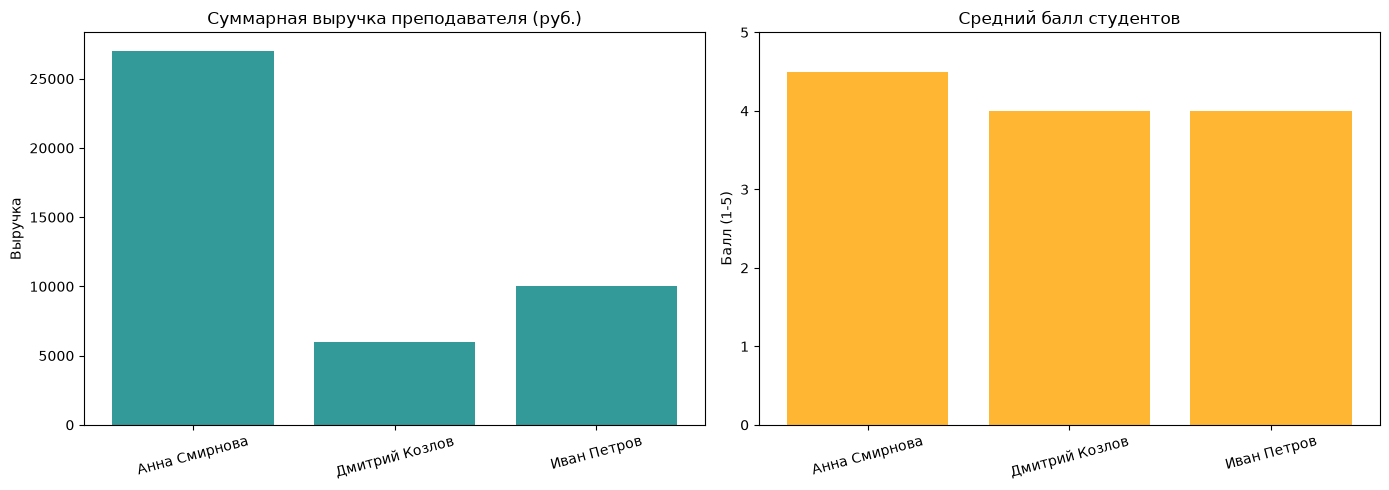

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# СОЗДАНИЕ БАЗЫ ДАННЫХ
teachers = pd.DataFrame({
    'teacher_id': [1, 2, 3],
    'name': ['Иван Петров', 'Анна Смирнова', 'Дмитрий Козлов']
})

courses = pd.DataFrame({
    'course_id': [101, 102, 103, 104],
    'title': ['Python для начинающих', 'SQL и базы данных', 'Машинное обучение', 'Веб-разработка'],
    'teacher_id': [1, 2, 2, 3],
    'price': [5000, 4000, 15000, 6000]
})

students = pd.DataFrame({
    'student_id': [1, 2, 3, 4, 5],
    'name': ['Алексей', 'Мария', 'Олег', 'Елена', 'Сергей'],
    'city': ['Москва', 'СПб', 'Москва', 'Казань', 'СПб']
})

enrollments = pd.DataFrame({
    'enrollment_id': [1, 2, 3, 4, 5, 6, 7],
    'student_id': [1, 1, 2, 2, 3, 4, 5],
    'course_id': [101, 102, 102, 103, 101, 104, 102],
    'grade': [5, 4, 5, 5, 3, 4, 4]
})
# Уровень 1: Студенты из Москвы
print("УРОВЕНЬ 1: Студенты из Москвы")
moscow_students = students[students['city'] == 'Москва']
print(moscow_students[['name', 'city']])

# УРОВЕНЬ 2: Студенты с оценкой 5
print("УРОВЕНЬ 2: Студенты с оценкой 5")

students_renamed = students.rename(columns={'name': 'student_name'})

merged_data = enrollments.merge(students_renamed, on='student_id') \
                        .merge(courses, on='course_id')

excellent_students = merged_data[merged_data['grade'] == 5]

print(excellent_students[['student_name', 'title', 'grade']]
      .rename(columns={'student_name': 'Студент', 'title': 'Курс', 'grade': 'Оценка'}))

# УРОВЕНЬ 3: Аналитика по преподавателям

print("УРОВЕНЬ 3: Аналитика по преподавателям")

teachers_renamed = teachers.rename(columns={'name': 'teacher_name'})

full_db = enrollments.merge(courses, on='course_id') \
                     .merge(teachers_renamed, on='teacher_id')

teacher_stats = full_db.groupby('teacher_name').agg(
    total_revenue=('price', 'sum'),
    avg_grade=('grade', 'mean'),
    students_count=('student_id', 'count')
).reset_index()

teacher_stats = teacher_stats.rename(columns={'teacher_name': 'Преподаватель'})
teacher_stats['avg_grade'] = teacher_stats['avg_grade'].round(2)

print(teacher_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(teacher_stats['Преподаватель'], teacher_stats['total_revenue'], color='teal', alpha=0.8)
axes[0].set_title('Суммарная выручка преподавателя (руб.)')
axes[0].set_ylabel('Выручка')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(teacher_stats['Преподаватель'], teacher_stats['avg_grade'], color='orange', alpha=0.8)
axes[1].set_title('Средний балл студентов')
axes[1].set_ylabel('Балл (1-5)')
axes[1].set_ylim(0, 5)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()